In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("news_popularity.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (93239, 11)


In [3]:
df.head()

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline,Facebook,GooglePlus,LinkedIn
0,99248.0,Obama Lays Wreath at Arlington National Cemetery,Obama Lays Wreath at Arlington National Cemete...,USA TODAY,obama,02-04-2002 00:00,0.000000,-0.053300,-1,-1,-1
1,10423.0,A Look at the Health of the Chinese Economy,"Tim Haywood, investment director business-unit...",Bloomberg,economy,20-09-2008 00:00,0.208333,-0.156386,-1,-1,-1
2,18828.0,Nouriel Roubini: Global Economy Not Back to 2008,"Nouriel Roubini, NYU professor and chairman at...",Bloomberg,economy,28-01-2012 00:00,-0.425210,0.139754,-1,-1,-1
3,27788.0,Finland GDP Expands In Q4,Finland's economy expanded marginally in the t...,RTT News,economy,01-03-2015 00:06,0.000000,0.026064,-1,-1,-1
4,27789.0,"Tourism, govt spending buoys Thai economy in J...",Tourism and public spending continued to boost...,The Nation - Thailand&#39;s English news,economy,01-03-2015 00:11,0.000000,0.141084,-1,-1,-1


In [4]:
df.tail()

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline,Facebook,GooglePlus,LinkedIn
93234,61851.0,Stocks rise as investors key in on US economy ...,The June employment report is viewed as a cruc...,MarketWatch,economy,07-07-2016 15:31,0.104284,0.044943,-1,3,5
93235,61865.0,Russian PM proposes to use conservative and to...,"In addition, establish stimulating economic po...",TASS,economy,07-07-2016 15:31,0.072194,0.000000,-1,0,1
93236,104793.0,Palestinian Government Uses Foreign Aid To Pay...,The Palestinian government spends nearly $140 ...,Daily Caller,palestine,07-07-2016 15:38,0.291667,-0.139754,5,1,0
93237,104794.0,Palestine Youth Orchestra prepares for first U...,Palestine Youth Orchestra prepares for first U...,Ahram Online,palestine,07-07-2016 15:59,0.121534,0.092313,0,0,0
93238,61870.0,Sausalito businesswoman wins $10000 in Microso...,"Goldstein, the proprietor of the TG Travel Gro...",East Bay Times,microsoft,07-07-2016 16:16,0.000000,0.054554,-1,1,0


In [5]:
print("Columns in dataset:")
print(df.columns.tolist())

Columns in dataset:
['IDLink', 'Title', 'Headline', 'Source', 'Topic', 'PublishDate', 'SentimentTitle', 'SentimentHeadline', 'Facebook', 'GooglePlus', 'LinkedIn']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93239 entries, 0 to 93238
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   IDLink             93239 non-null  float64
 1   Title              93239 non-null  object 
 2   Headline           93224 non-null  object 
 3   Source             92960 non-null  object 
 4   Topic              93239 non-null  object 
 5   PublishDate        93239 non-null  object 
 6   SentimentTitle     93239 non-null  float64
 7   SentimentHeadline  93239 non-null  float64
 8   Facebook           93239 non-null  int64  
 9   GooglePlus         93239 non-null  int64  
 10  LinkedIn           93239 non-null  int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 7.8+ MB


In [7]:
df.describe()

,IDLink,SentimentTitle,SentimentHeadline,Facebook,GooglePlus,LinkedIn
count,93239.000000,93239.000000,93239.000000,93239.000000,93239.000000,93239.000000
mean,51560.653257,-0.005411,-0.027493,113.141336,3.888362,16.547957
std,30391.078704,0.136431,0.141964,620.173233,18.492648,154.459048
min,1.000000,-0.950694,-0.755433,-1.000000,-1.000000,-1.000000
25%,24301.500000,-0.079057,-0.114574,0.000000,0.000000,0.000000
50%,52275.000000,0.000000,-0.026064,5.000000,0.000000,0.000000
75%,76585.500000,0.064255,0.059709,33.000000,2.000000,4.000000
max,104802.000000,0.962354,0.964646,49211.000000,1267.000000,20341.000000


In [8]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
IDLink                 0
Title                  0
Headline              15
Source               279
Topic                  0
PublishDate            0
SentimentTitle         0
SentimentHeadline      0
Facebook               0
GooglePlus             0
LinkedIn               0
dtype: int64


In [9]:
# Fill missing text values
df['Headline'] = df['Headline'].fillna('')

# Fill missing Source values
df['Source'] = df['Source'].fillna('Unknown')

print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
IDLink               0
Title                0
Headline             0
Source               0
Topic                0
PublishDate          0
SentimentTitle       0
SentimentHeadline    0
Facebook             0
GooglePlus           0
LinkedIn             0
dtype: int64


In [10]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 4


In [11]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (93235, 11)


In [12]:
print(df['SentimentTitle'].describe())

count    93235.000000
mean        -0.005410
std          0.136432
min         -0.950694
25%         -0.079057
50%          0.000000
75%          0.064277
max          0.962354
Name: SentimentTitle, dtype: float64


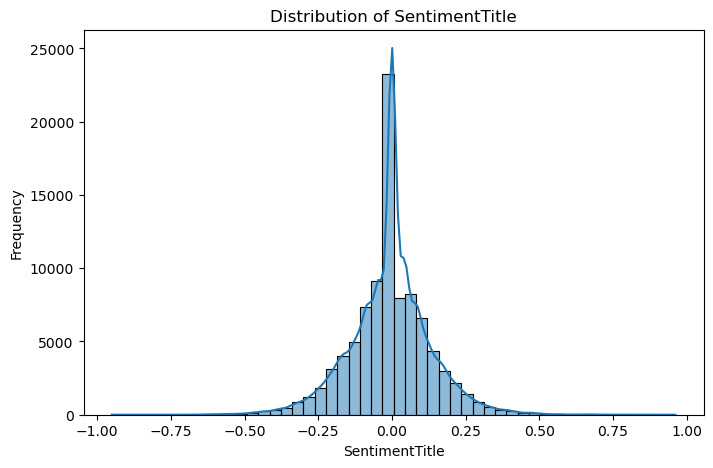

In [13]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['SentimentTitle'],
    bins=50,
    kde=True
)

plt.title("Distribution of SentimentTitle")
plt.xlabel("SentimentTitle")
plt.ylabel("Frequency")

plt.show()

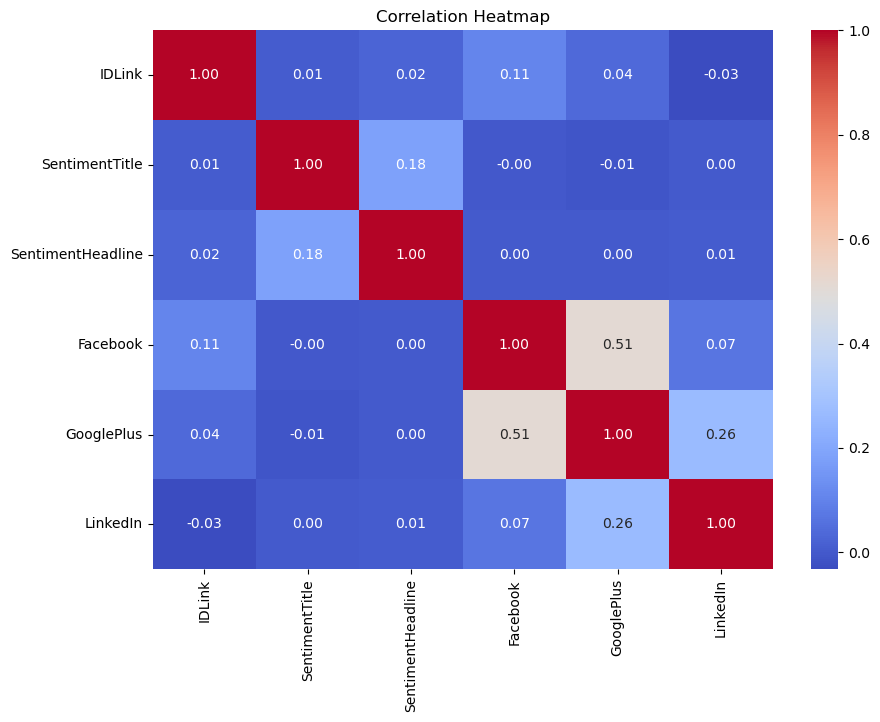

In [14]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
target_corr = correlation['SentimentTitle'].sort_values(
    ascending=False
)

print(target_corr)

SentimentTitle       1.000000
SentimentHeadline    0.183569
IDLink               0.005046
LinkedIn             0.003410
Facebook            -0.003810
GooglePlus          -0.010269
Name: SentimentTitle, dtype: float64


In [16]:
df['Facebook_log'] = np.log1p(
    df['Facebook'].clip(lower=0)
)

df['GooglePlus_log'] = np.log1p(
    df['GooglePlus'].clip(lower=0)
)

df['LinkedIn_log'] = np.log1p(
    df['LinkedIn'].clip(lower=0)
)

print(df[
    [
        'Facebook',
        'Facebook_log',
        'GooglePlus',
        'GooglePlus_log',
        'LinkedIn',
        'LinkedIn_log'
    ]
].head())

   Facebook  Facebook_log  GooglePlus  GooglePlus_log  LinkedIn  LinkedIn_log
0        -1           0.0          -1             0.0        -1           0.0
1        -1           0.0          -1             0.0        -1           0.0
2        -1           0.0          -1             0.0        -1           0.0
3        -1           0.0          -1             0.0        -1           0.0
4        -1           0.0          -1             0.0        -1           0.0


In [17]:
print(df[['Title', 'Headline']].head(10))

                                               Title  \
0   Obama Lays Wreath at Arlington National Cemetery   
1        A Look at the Health of the Chinese Economy   
2   Nouriel Roubini: Global Economy Not Back to 2008   
3                          Finland GDP Expands In Q4   
4  Tourism, govt spending buoys Thai economy in J...   
5  Intellitec Solutions to Host 13th Annual Sprin...   
6                                Monday, 29 Feb 2016   
7  Obama, stars pay a musical tribute to Ray Charles   
8  Fire claims more than 100-year-old barn in Han...   
9        Microsoft's new Windows 10 ad targets Apple   

                                            Headline  
0  Obama Lays Wreath at Arlington National Cemete...  
1  Tim Haywood, investment director business-unit...  
2  Nouriel Roubini, NYU professor and chairman at...  
3  Finland's economy expanded marginally in the t...  
4  Tourism and public spending continued to boost...  
5  Over 100 attendees expected to see latest vers... 

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [19]:
X = df[
    [
        'Title',
        'Headline',
        'SentimentHeadline',
        'Facebook_log',
        'GooglePlus_log',
        'LinkedIn_log'
    ]
]

y = df['SentimentTitle']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (93235, 6)
y shape: (93235,)


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (74588, 6)
X_test : (18647, 6)
y_train: (74588,)
y_test : (18647,)


In [21]:
title_tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_title = title_tfidf.fit_transform(
    X_train['Title']
)

X_test_title = title_tfidf.transform(
    X_test['Title']
)

print("Title TF-IDF train shape:", X_train_title.shape)
print("Title TF-IDF test shape:", X_test_title.shape)

Title TF-IDF train shape: (74588, 30000)
Title TF-IDF test shape: (18647, 30000)


In [22]:
headline_tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_headline = headline_tfidf.fit_transform(
    X_train['Headline']
)

X_test_headline = headline_tfidf.transform(
    X_test['Headline']
)

print(
    "Headline TF-IDF train shape:",
    X_train_headline.shape
)

Headline TF-IDF train shape: (74588, 20000)


In [23]:
from scipy.sparse import hstack

numeric_train = X_train[
    [
        'SentimentHeadline',
        'Facebook_log',
        'GooglePlus_log',
        'LinkedIn_log'
    ]
].values

numeric_test = X_test[
    [
        'SentimentHeadline',
        'Facebook_log',
        'GooglePlus_log',
        'LinkedIn_log'
    ]
].values

X_train_final = hstack([
    X_train_title,
    X_train_headline,
    numeric_train
])

X_test_final = hstack([
    X_test_title,
    X_test_headline,
    numeric_test
])

print("Final train shape:", X_train_final.shape)
print("Final test shape :", X_test_final.shape)

Final train shape: (74588, 50004)
Final test shape : (18647, 50004)


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print("\n", name)
    print("-" * 40)
    print("MAE :", round(mae, 4))
    print("MSE :", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R²  :", round(r2, 4))

    return [name, mae, mse, rmse, r2]

In [25]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train_final, y_train)

linear_pred = linear_model.predict(X_test_final)

results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    )
)


 Linear Regression
----------------------------------------
MAE : 0.081
MSE : 0.0124
RMSE: 0.1115
R²  : 0.3301


In [26]:
from sklearn.tree import DecisionTreeRegressor

decision_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    random_state=42
)

decision_tree.fit(X_train_final, y_train)

dt_pred = decision_tree.predict(X_test_final)

results.append(
    evaluate_model(
        "Decision Tree Regression",
        y_test,
        dt_pred
    )
)


 Decision Tree Regression
----------------------------------------
MAE : 0.0863
MSE : 0.0144
RMSE: 0.1199
R²  : 0.2248


In [27]:
from sklearn.ensemble import RandomForestRegressor

random_forest = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(
    X_train_final,
    y_train
)

rf_pred = random_forest.predict(
    X_test_final
)

results.append(
    evaluate_model(
        "Random Forest Regression",
        y_test,
        rf_pred
    )
)


 Random Forest Regression
----------------------------------------
MAE : 0.085
MSE : 0.014
RMSE: 0.1182
R²  : 0.2463


In [28]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_boost = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_boost.fit(
    X_train_final,
    y_train
)

gb_pred = gradient_boost.predict(
    X_test_final
)

results.append(
    evaluate_model(
        "Gradient Boosting Regression",
        y_test,
        gb_pred
    )
)


 Gradient Boosting Regression
----------------------------------------
MAE : 0.0847
MSE : 0.0138
RMSE: 0.1176
R²  : 0.2544


In [29]:
results_df = pd.DataFrame(
    results,
    columns=[
        'Algorithm',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

results_df = results_df.sort_values(
    by='R2',
    ascending=False
)

results_df

,Algorithm,MAE,MSE,RMSE,R2
0,Linear Regression,0.080991,0.012422,0.111453,0.330130
3,Gradient Boosting Regression,0.084704,0.013825,0.117582,0.254431
2,Random Forest Regression,0.085008,0.013975,0.118218,0.246342
1,Decision Tree Regression,0.086272,0.014375,0.119894,0.224813


In [30]:
best_model = results_df.iloc[0]

print("Best Algorithm:", best_model['Algorithm'])
print("MAE:", round(best_model['MAE'], 4))
print("MSE:", round(best_model['MSE'], 4))
print("RMSE:", round(best_model['RMSE'], 4))
print("R²:", round(best_model['R2'], 4))

Best Algorithm: Linear Regression
MAE: 0.081
MSE: 0.0124
RMSE: 0.1115
R²: 0.3301


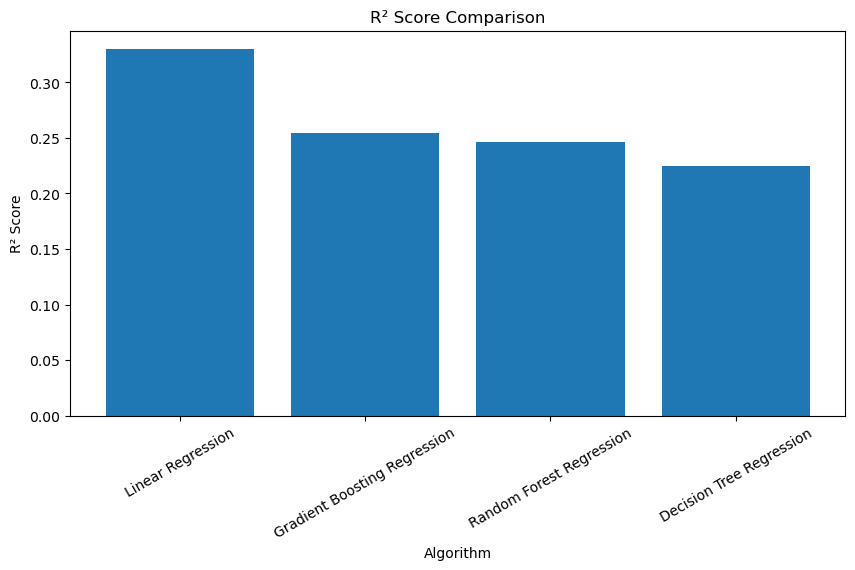

In [31]:
plt.figure(figsize=(10,5))

plt.bar(
    results_df['Algorithm'],
    results_df['R2']
)

plt.title("R² Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("R² Score")
plt.xticks(rotation=30)

plt.show()

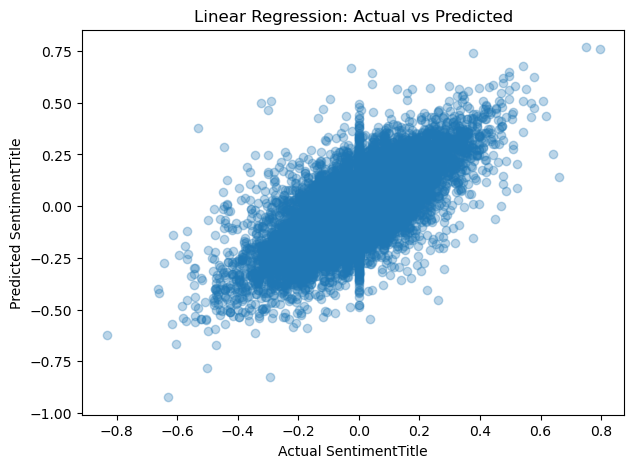

In [32]:
plt.figure(figsize=(7,5))

plt.scatter(
    y_test,
    linear_pred,
    alpha=0.3
)

plt.xlabel("Actual SentimentTitle")
plt.ylabel("Predicted SentimentTitle")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()